## ✈ Airline Operational Performance Dashboard ✈

In this project, we are going to build a dashboard that helps airline managers understand operational performance and identify areas for improvement.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

# Set random seed for reproducibility
np.random.seed(42)

# Generate synthetic flight data
n_flights = 1000
airlines = ['Delta Air Lines', 'United Airlines', 'American Airlines', 'Southwest Airlines', 'JetBlue']
airports = ['ATL', 'ORD', 'DFW', 'DEN', 'LAX', 'JFK', 'SFO']

start_date = datetime(2023, 10, 1)
dates = [start_date + timedelta(days=int(i)) for i in np.random.randint(0, 30, size=n_flights)]

# Base probabilities for cancellation and delays
cancelled = np.random.choice([0, 1], size=n_flights, p=[0.97, 0.03])

# Generate arrival delay minutes (mostly 0 or small, some large delays)
arr_delay = np.random.exponential(scale=12, size=n_flights)
# Adjust delay values to simulate real-world metrics
arr_delay = np.where(np.random.rand(n_flights) > 0.4, arr_delay, 0)
arr_delay = np.where(cancelled == 1, 0, arr_delay).astype(int)

# Create DataFrame
flights_df = pd.DataFrame({
    'Flight_Date': dates,
    'Airline': np.random.choice(airlines, size=n_flights),
    'Origin': np.random.choice(airports, size=n_flights),
    'Dest': np.random.choice(airports, size=n_flights),
    'Cancelled': cancelled,
    'Arr_Delay_Min': arr_delay
})

# Ensure origin != destination
flights_df = flights_df[flights_df['Origin'] != flights_df['Dest']].reset_index(drop=True)

# Add specific delay causes for delayed flights (> 15 mins)
delayed_mask = (flights_df['Arr_Delay_Min'] > 15) & (flights_df['Cancelled'] == 0)
n_delayed = delayed_mask.sum()

flights_df['Carrier_Delay'] = 0
flights_df['Weather_Delay'] = 0
flights_df['NAS_Delay'] = 0
flights_df['Late_Aircraft_Delay'] = 0

# Distribute total arrival delay into causes
for idx in flights_df[delayed_mask].index:
    total_delay = flights_df.loc[idx, 'Arr_Delay_Min']
    shares = np.random.dirichlet(np.ones(4)) * total_delay
    flights_df.loc[idx, ['Carrier_Delay', 'Weather_Delay', 'NAS_Delay', 'Late_Aircraft_Delay']] = shares.astype(int)

display(flights_df.head())

,Flight_Date,Airline,Origin,Dest,Cancelled,Arr_Delay_Min,Carrier_Delay,Weather_Delay,NAS_Delay,Late_Aircraft_Delay
0,2023-10-20,Southwest Airlines,LAX,JFK,0,2,0,0,0,0
1,2023-10-29,JetBlue,JFK,DEN,0,8,0,0,0,0
2,2023-10-15,JetBlue,LAX,ATL,0,14,0,0,0,0
3,2023-10-11,Southwest Airlines,SFO,ORD,0,1,0,0,0,0
4,2023-10-29,United Airlines,ORD,DFW,0,3,0,0,0,0


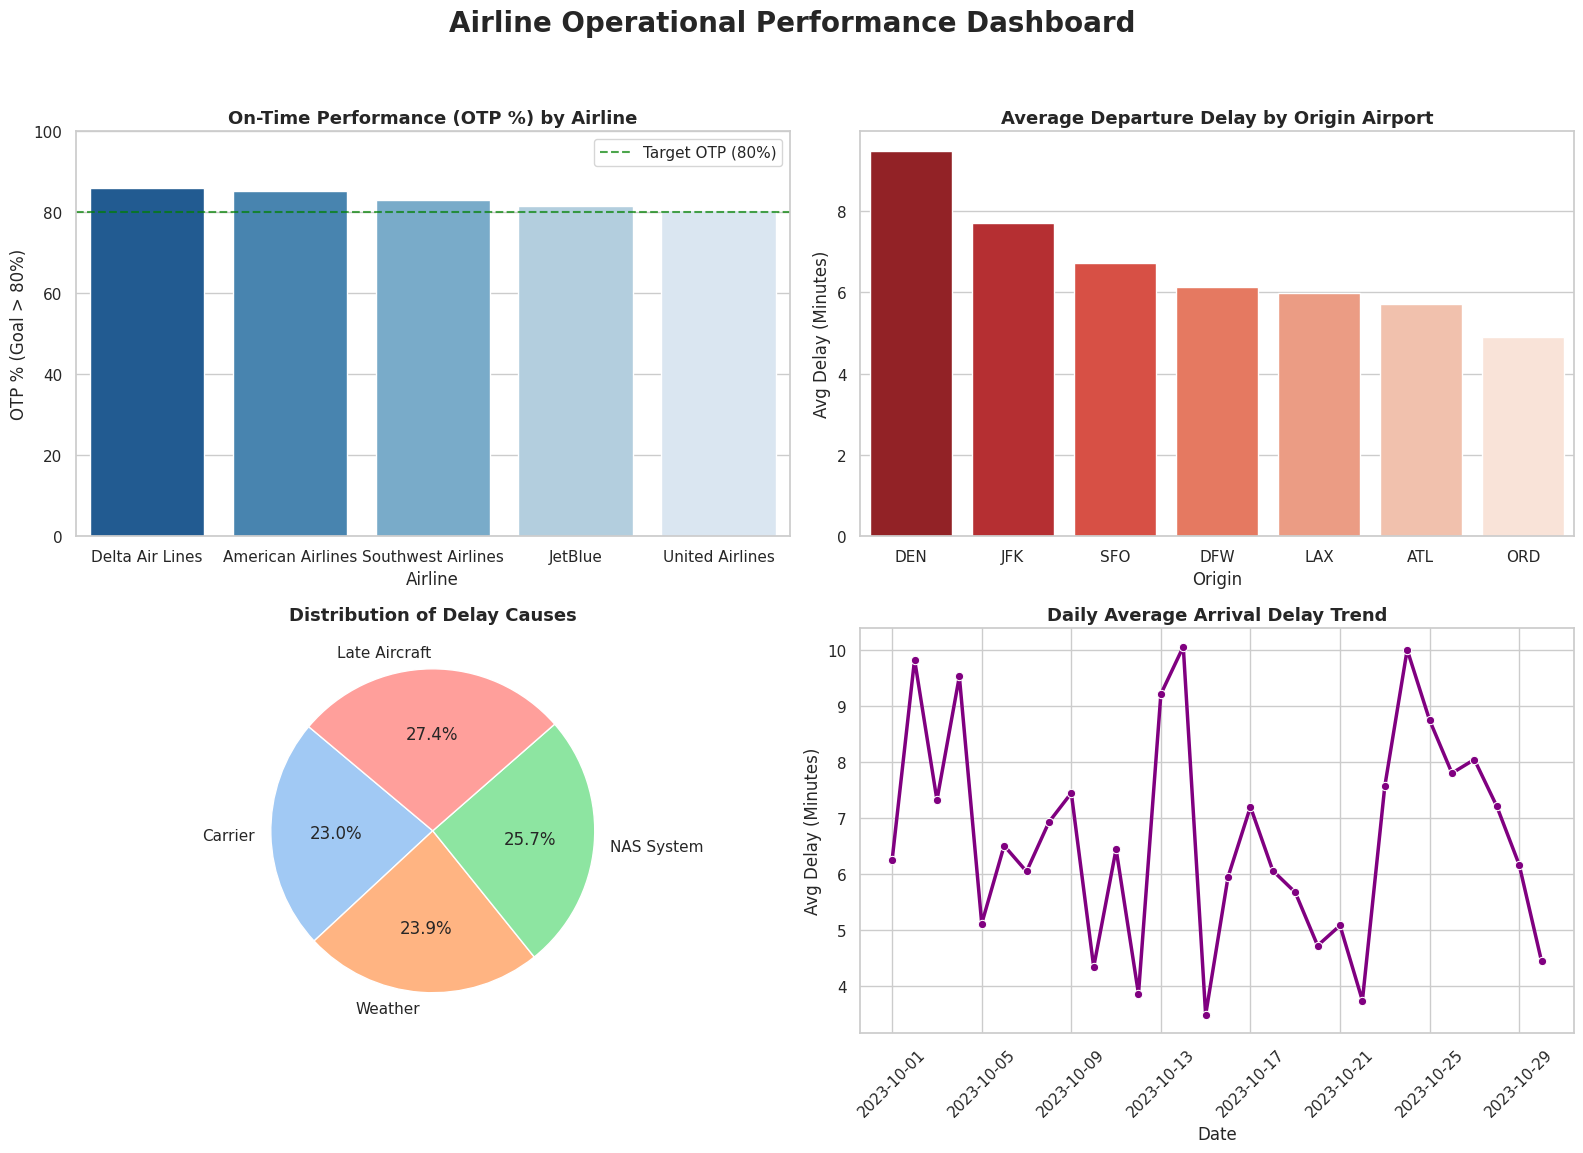

Executive Summary:
- Fleet OTP: 83.3% | Avg Delay: 6.6 mins | Cancellation Rate: 2.75%
- Most delayed airline: Southwest Airlines (6.9 mins average)
- Most bottlenecked airport: DEN (9.5 mins average)


In [ ]:
sns.set_theme(style="whitegrid")

# 1. Prepare Dashboard Metrics
total_flights = len(flights_df)
active_flights = flights_df[flights_df['Cancelled'] == 0]
total_cancelled = flights_df['Cancelled'].sum()
cancellation_rate = (total_cancelled / total_flights) * 100

# On-Time Performance (OTP %): Delay <= 15 minutes
otp_overall = (active_flights['Arr_Delay_Min'] <= 15).sum() / total_flights * 100
avg_delay_overall = active_flights['Arr_Delay_Min'].mean()

# Airline KPI summaries
airline_stats = flights_df.groupby('Airline').agg(
    Total=('Cancelled', 'count'),
    Cancelled=('Cancelled', 'sum'),
    Avg_Delay=('Arr_Delay_Min', lambda x: x[flights_df.loc[x.index, 'Cancelled'] == 0].mean())
).reset_index()

airline_stats['OTP_%'] = [
    (flights_df[(flights_df['Airline'] == a) & (flights_df['Cancelled'] == 0)]['Arr_Delay_Min'] <= 15).sum() /
    len(flights_df[flights_df['Airline'] == a]) * 100
    for a in airline_stats['Airline']
]

# Airport summaries
airport_delays = active_flights.groupby('Origin')['Arr_Delay_Min'].mean().reset_index().sort_values(by='Arr_Delay_Min', ascending=False)

# Delay Causes aggregation
delay_causes = active_flights[active_flights['Arr_Delay_Min'] > 15][['Carrier_Delay', 'Weather_Delay', 'NAS_Delay', 'Late_Aircraft_Delay']].sum()

# Delay over time
trend_df = active_flights.groupby('Flight_Date')['Arr_Delay_Min'].mean().reset_index()

# 2. Draw 2x2 Dashboard Visualizations
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Airline Operational Performance Dashboard', fontsize=20, fontweight='bold', y=0.96)

# Subplot 1: On-Time Performance by Airline
sns.barplot(ax=axes[0, 0], data=airline_stats.sort_values(by='OTP_%', ascending=False), x='Airline', y='OTP_%', hue='Airline', palette='Blues_r', legend=False)
axes[0, 0].set_title('On-Time Performance (OTP %) by Airline', fontsize=13, fontweight='semibold')
axes[0, 0].set_ylabel('OTP % (Goal > 80%)')
axes[0, 0].set_ylim(0, 100)
axes[0, 0].axhline(80, color='green', linestyle='--', alpha=0.7, label='Target OTP (80%)')
axes[0, 0].legend()

# Subplot 2: Delay Patterns by Departure Airport
sns.barplot(ax=axes[0, 1], data=airport_delays, x='Origin', y='Arr_Delay_Min', hue='Origin', palette='Reds_r', legend=False)
axes[0, 1].set_title('Average Departure Delay by Origin Airport', fontsize=13, fontweight='semibold')
axes[0, 1].set_ylabel('Avg Delay (Minutes)')

# Subplot 3: Delay Root-Cause Investigation
axes[1, 0].pie(delay_causes, labels=['Carrier', 'Weather', 'NAS System', 'Late Aircraft'], autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
axes[1, 0].set_title('Distribution of Delay Causes', fontsize=13, fontweight='semibold')

# Subplot 4: Average Delay Trend Over Time
sns.lineplot(ax=axes[1, 1], data=trend_df, x='Flight_Date', y='Arr_Delay_Min', color='purple', linewidth=2.5, marker='o')
axes[1, 1].set_title('Daily Average Arrival Delay Trend', fontsize=13, fontweight='semibold')
axes[1, 1].set_ylabel('Avg Delay (Minutes)')
axes[1, 1].set_xlabel('Date')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

# Print summary highlights
print(f"Executive Summary:")
print(f"- Fleet OTP: {otp_overall:.1f}% | Avg Delay: {avg_delay_overall:.1f} mins | Cancellation Rate: {cancellation_rate:.2f}%")
print(f"- Most delayed airline: {airline_stats.loc[airline_stats['Avg_Delay'].idxmax(), 'Airline']} ({airline_stats['Avg_Delay'].max():.1f} mins average)")
print(f"- Most bottlenecked airport: {airport_delays.iloc[0]['Origin']} ({airport_delays.iloc[0]['Arr_Delay_Min']:.1f} mins average)")